In [1]:
import os
import time
import torch
import random
import numpy as np
import csv
from tqdm import tqdm

import torch
import math  # <-- Add this line
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder

from sklearn.metrics import classification_report


# =========================
# ✅ 调用你的模型
# =========================
from FMGFormer import FMGFormer

# =========================
# 🔒 关键：安全版 ImageFolder（过滤 .ipynb_checkpoints）
# =========================
class CleanImageFolder(ImageFolder):
    def find_classes(self, directory):
        classes = []
        for d in os.listdir(directory):
            full = os.path.join(directory, d)
            if os.path.isdir(full) and not d.startswith("."):
                classes.append(d)

        classes.sort()
        class_to_idx = {cls: i for i, cls in enumerate(classes)}
        return classes, class_to_idx


# =========================
# 🔒 固定：训练 / 验证函数
# =========================
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0, 0, 0

    for imgs, labels in tqdm(loader, desc="Train", leave=False):
        imgs, labels = imgs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * imgs.size(0)
        preds = outputs.argmax(1)
        correct += (preds == labels).sum().item()
        total += imgs.size(0)

    return total_loss / total, correct / total


def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0, 0, 0

    with torch.no_grad():
        for imgs, labels in tqdm(loader, desc="Eval", leave=False):
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * imgs.size(0)
            preds = outputs.argmax(1)
            correct += (preds == labels).sum().item()
            total += imgs.size(0)

    return total_loss / total, correct / total


# =========================
# 📁 数据路径
# =========================
data_root = "./datasets"
train_dir = os.path.join(data_root, "train")
val_dir   = os.path.join(data_root, "val")
test_dir  = os.path.join(data_root, "test")


# =========================
# ⚙️ 训练配置
# =========================
img_size = 224
num_classes = 10
batch_size = 32
num_epochs = 100
lr = 1e-4
num_workers = 10

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


# =========================
# 🎲 固定随机种子
# =========================
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)


# =========================
# 🖼 数据增强
# =========================
train_transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

val_transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])


# =========================
# 📦 Dataset & DataLoader
# =========================
train_ds = CleanImageFolder(train_dir, transform=train_transform)
val_ds   = CleanImageFolder(val_dir, transform=val_transform)
test_ds  = CleanImageFolder(test_dir, transform=val_transform)

print("Class mapping:", train_ds.class_to_idx)

# 🔒 类别数硬校验（非常重要）
assert len(train_ds.classes) == num_classes, \
    f"❌ 类别数不一致: dataset={len(train_ds.classes)} vs num_classes={num_classes}"

train_loader = DataLoader(
    train_ds, batch_size=batch_size,
    shuffle=True, num_workers=num_workers, pin_memory=True
)

val_loader = DataLoader(
    val_ds, batch_size=batch_size,
    shuffle=False, num_workers=num_workers, pin_memory=True
)

test_loader = DataLoader(
    test_ds, batch_size=batch_size,
    shuffle=False, num_workers=num_workers, pin_memory=True
)


# =========================
# ⭐ 模型
# =========================
model = FMGFormer(
    num_classes=num_classes
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=lr)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=num_epochs
)

Using device: cuda
GPU: NVIDIA GeForce RTX 4090
Class mapping: {'Bacterial_leaf_blight': 0, 'Bacterial_leaf_streak': 1, 'Bacterial_panicle_blight': 2, 'Blast': 3, 'Brown_spot': 4, 'Dead_heart': 5, 'Downy_mildew': 6, 'Hispa': 7, 'Normal': 8, 'Tungro': 9}


In [2]:
import torch
from thop import profile

# 确保模型在正确的设备上
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)  # 将模型移到设备

# 切换到评估模式
model.eval()

# 使用适当的 img_size
img_size = 224  # 可以根据实际输入尺寸调整
dummy_input = torch.randn(1, 3, img_size, img_size).to(device)

# 执行一次前向传播，确保模型的计算路径被启用
model(dummy_input)

# 计算 FLOPs 和参数量
flops, params = profile(model, inputs=(dummy_input,))

# 计算模型大小（MB）
model_size_bytes = sum(p.numel() * p.element_size() for p in model.parameters())
model_size_mb = model_size_bytes / (1024 * 1024)  # 转换为MB

total_layers = len(list(model.modules()))

# 转换为百万 (M)
params_m = params / 1e6  

# 转换 FLOPs 为不同单位
flops_g = flops / 1e9  # 转换为吉浮点运算 (GFLOPs)
flops_m = flops / 1e6  # 转换为百万浮点运算 (MFLOPs)
flops_k = flops / 1e3  # 转换为千浮点运算 (KFLOPs)

# 打印总结信息
print(f"\nmodel summary: {total_layers} layers, "
      f"{params_m:.2f}M parameters, {params_m:.2f}M gradients, "
      f"{flops_g:.2f} GFLOPs, {flops_m:.1f} MFLOPs, {flops_k:.1f} KFLOPs, "
      f"{model_size_mb:.2f} MB model size")

[INFO] Register count_convNd() for <class 'torch.nn.modules.conv.Conv2d'>.
[INFO] Register count_normalization() for <class 'torch.nn.modules.batchnorm.BatchNorm2d'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.activation.ReLU'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.container.Sequential'>.
[INFO] Register count_adap_avgpool() for <class 'torch.nn.modules.pooling.AdaptiveAvgPool2d'>.
[INFO] Register count_linear() for <class 'torch.nn.modules.linear.Linear'>.
[INFO] Register count_normalization() for <class 'torch.nn.modules.normalization.LayerNorm'>.
[INFO] Register count_convNd() for <class 'torch.nn.modules.conv.Conv1d'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.dropout.Dropout'>.

model summary: 452 layers, 1.93M parameters, 1.93M gradients, 0.66 GFLOPs, 658.6 MFLOPs, 658638.9 KFLOPs, 7.35 MB model size


In [3]:

# ------------------- 保存目录 -------------------
os.makedirs('./Result/5/Train_csv', exist_ok=True)
os.makedirs('./Result/5/model_save', exist_ok=True)
csv_file = './Result/5/Train_csv/basel.csv'
best_model_path = os.path.join('./Result/5/model_save', 'best.pth')
last_model_path = os.path.join('./Result/5/model_save', 'last.pth')

# ------------------- resume_mode 配置 -------------------
resume_mode = "last"  # "last" / "best" / "none"
start_epoch = 1
best_val_acc = 0.0

if resume_mode.lower() == "last" and os.path.exists(last_model_path):
    checkpoint = torch.load(last_model_path, map_location=device)
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
    start_epoch = checkpoint['epoch'] + 1
    best_val_acc = checkpoint.get('best_val_acc', 0)
    print(f"✅ 从上次最新 checkpoint 继续训练：epoch {start_epoch}, best_val_acc={best_val_acc:.4f}")

elif resume_mode.lower() == "best" and os.path.exists(best_model_path):
    checkpoint = torch.load(best_model_path, map_location=device)
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
    start_epoch = checkpoint['epoch'] + 1
    best_val_acc = checkpoint.get('best_val_acc', 0)
    print(f"✅ 从最佳模型继续训练：epoch {start_epoch}, best_val_acc={best_val_acc:.4f}")

else:
    print("⚡ 从头开始训练")


# ------------------- 初始化 CSV -------------------
if not os.path.exists(csv_file):
    with open(csv_file, mode='w', newline='') as f:
        writer = csv.writer(f)
        writer.writerow(['epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc'])


# ------------------- 训练循环（完全未改） -------------------
for epoch in range(start_epoch, num_epochs + 1):
    t0 = time.time()

    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )
    val_loss, val_acc = evaluate(
        model, val_loader, criterion, device
    )
    scheduler.step()

    print(f"[Epoch {epoch}/{num_epochs}] time:{time.time()-t0:.1f}s "
          f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
          f"val_loss={val_loss:.4f} val_acc={val_acc:.4f}")

    torch.save({
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'train_loss': train_loss,
        'train_acc': train_acc,
        'val_loss': val_loss,
        'val_acc': val_acc,
        'best_val_acc': best_val_acc
    }, last_model_path)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'train_loss': train_loss,
            'train_acc': train_acc,
            'val_loss': val_loss,
            'val_acc': val_acc,
            'best_val_acc': best_val_acc
        }, best_model_path)

    with open(csv_file, mode='a', newline='') as f:
        writer = csv.writer(f)
        writer.writerow([epoch, train_loss, train_acc, val_loss, val_acc])

✅ 从上次最新 checkpoint 继续训练：epoch 101, best_val_acc=0.9730


In [4]:
import os
import time
import torch
import numpy as np
from tqdm import tqdm

# ==================================================
# Assumptions:
#   model        : 已加载权重的 MobileNetV3
#   test_loader  : DataLoader(ImageFolder)
#   test_ds      : ImageFolder dataset
#   device       : cuda / cpu
# ==================================================

model.eval()

# -------------------------
# Containers
# -------------------------
preds_all = []
labels_all = []
logits_all = []

# -------------------------
# Timing containers
# -------------------------
total_infer_time = 0.0
total_images = 0
latency_list = []   # per-image latency (seconds)

# =========================
# Warm-up (GPU 必须)
# =========================
with torch.no_grad():
    for imgs, _ in test_loader:
        imgs = imgs.to(device)
        _ = model(imgs)
        if device.type == "cuda":
            torch.cuda.synchronize()
        break

# =========================
# Test loop
# =========================
with torch.no_grad():
    for imgs, labels in tqdm(test_loader, desc="Test"):
        imgs = imgs.to(device)
        labels = labels.to(device)

        # --------- timing start ---------
        if device.type == "cuda":
            torch.cuda.synchronize()
        start_time = time.perf_counter()

        outputs = model(imgs)  # logits

        if device.type == "cuda":
            torch.cuda.synchronize()
        end_time = time.perf_counter()
        # --------- timing end ---------

        batch_time = end_time - start_time
        batch_size = imgs.size(0)

        total_infer_time += batch_time
        total_images += batch_size

        # per-image latency
        per_image_latency = batch_time / batch_size
        latency_list.extend([per_image_latency] * batch_size)

        preds = outputs.argmax(dim=1)

        preds_all.extend(preds.cpu().tolist())
        labels_all.extend(labels.cpu().tolist())
        logits_all.append(outputs.cpu())

# =========================
# Stack outputs
# =========================
y_true = torch.tensor(labels_all)
y_pred = torch.tensor(preds_all)
logits_all = torch.cat(logits_all, dim=0)   # [N, C]

total = y_true.numel()

# =========================
# Top-1 / Top-5 Accuracy
# =========================
num_classes = logits_all.size(1)
max_k = min(5, num_classes)

_, topk_preds = logits_all.topk(max_k, dim=1, largest=True, sorted=True)
y_true_expand = y_true.view(-1, 1).expand_as(topk_preds)

topk_correct = (topk_preds == y_true_expand)

top1_acc = topk_correct[:, :1].any(dim=1).float().mean().item() * 100
top5_acc = topk_correct.any(dim=1).float().mean().item() * 100

# =========================
# Accuracy / Error Rate
# =========================
correct = (y_true == y_pred).sum().item()
test_acc = correct / total
test_error = 1.0 - test_acc

# =========================
# Precision (macro)
# =========================
num_classes = len(test_ds.classes)
conf_mat = torch.zeros(num_classes, num_classes, dtype=torch.int64)

for t, p in zip(y_true, y_pred):
    conf_mat[t, p] += 1

precision_per_class = []
for c in range(num_classes):
    tp = conf_mat[c, c]
    fp = conf_mat[:, c].sum() - tp
    if tp + fp == 0:
        precision_per_class.append(0.0)
    else:
        precision_per_class.append((tp / (tp + fp)).item())

test_precision = sum(precision_per_class) / num_classes

# =========================
# FPS / Latency / Inference Speed
# =========================
fps = total_images / total_infer_time

latency_np = np.array(latency_list) * 1000  # ms
avg_latency = latency_np.mean()
max_latency = latency_np.max()
p95_latency = np.percentile(latency_np, 95)

# 推理速度的等价表示
infer_time_per_image_ms = 1000.0 / fps
avg_batch_time_ms = (total_infer_time / len(test_loader)) * 1000
images_per_ms = fps / 1000.0

# =========================
# Print results
# =========================
print("\n========== Test Results ==========")
print(f"Test samples             : {total}")
print(f"Top-1 Accuracy (%)       : {top1_acc:.2f}")
#print(f"Top-5 Accuracy (%)       : {top5_acc:.2f}")
print(f"Accuracy                 : {test_acc:.4f}")
print(f"Error Rate               : {test_error:.4f}")
print(f"Precision (macro)        : {test_precision:.4f}")
print("----------------------------------")
print(f"FPS                      : {fps:.2f}")
print(f"Inference Time / Image   : {infer_time_per_image_ms:.2f} ms")
print(f"Inference Time / Batch   : {avg_batch_time_ms:.2f} ms")
print(f"Images per ms            : {images_per_ms:.4f}")
print("----------------------------------")
print(f"Avg Latency (ms)         : {avg_latency:.2f}")
print(f"Max Latency (ms)         : {max_latency:.2f}")
print(f"P95 Latency (ms)         : {p95_latency:.2f}")
print("==================================\n")

# =========================
# Save predictions
# =========================
save_dir = "./Result/5"
os.makedirs(save_dir, exist_ok=True)

out_pred_file = os.path.join(save_dir, "test_preds.txt")
with open(out_pred_file, "w") as f:
    for p, t in zip(preds_all, labels_all):
        f.write(f"{p}\t{t}\n")

print(f"Predictions saved to {out_pred_file}")

Test: 100%|██████████| 33/33 [00:01<00:00, 31.64it/s]


========== Test Results ==========
Test samples             : 1048
Top-1 Accuracy (%)       : 97.04
Accuracy                 : 0.9704
Error Rate               : 0.0296
Precision (macro)        : 0.9617
----------------------------------
FPS                      : 2428.06
Inference Time / Image   : 0.41 ms
Inference Time / Batch   : 13.08 ms
Images per ms            : 2.4281
----------------------------------
Avg Latency (ms)         : 0.41
Max Latency (ms)         : 3.97
P95 Latency (ms)         : 1.26

Predictions saved to ./Result/5/test_preds.txt


In [5]:
# 获取类别到ID的映射字典
from sklearn.metrics import accuracy_score

id2name = {idx: cls for cls, idx in train_ds.class_to_idx.items()}
model.eval()
y_true_list, y_pred_probs_list = [], []

# 1. 收集模型预测和真实标签
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        labels = labels.to(device)
        outputs = model(imgs)  # Now expecting only the logits (not two outputs)
        probs = torch.softmax(outputs, dim=1)
        y_pred_probs_list.append(probs.cpu())
        y_true_list.append(labels.cpu())

y_pred_probs = torch.cat(y_pred_probs_list, dim=0)  # [num_samples, num_classes]
y_true = torch.cat(y_true_list, dim=0)             # [num_samples]

# 2. 预测类别
y_pred = torch.argmax(y_pred_probs, dim=1)

# =================== 平均置信度 ===================
confidence_scores = torch.max(y_pred_probs, dim=1).values  # 每个样本最大预测概率
avg_confidence_per_class = []

print("\n===== 平均置信度 =====")
for cls in range(num_classes):
    idxs = (y_true == cls)
    if idxs.sum() > 0:
        avg_conf = confidence_scores[idxs].mean().item()
    else:
        avg_conf = 0.0
    avg_confidence_per_class.append(avg_conf)
    print(f"Class {id2name.get(cls, str(cls))}: {avg_conf:.4f}")  # Print class name using id2name

# =================== 每类指标 ===================
tp, fp, fn = [], [], []

for cls in range(num_classes):
    tp_cls = ((y_pred == cls) & (y_true == cls)).sum().item()
    fp_cls = ((y_pred == cls) & (y_true != cls)).sum().item()
    fn_cls = ((y_pred != cls) & (y_true == cls)).sum().item()
    tp.append(tp_cls)
    fp.append(fp_cls)
    fn.append(fn_cls)

precision_per_class = [tp[i] / (tp[i] + fp[i]) if (tp[i] + fp[i]) > 0 else 0.0 for i in range(num_classes)]
recall_per_class = [tp[i] / (tp[i] + fn[i]) if (tp[i] + fn[i]) > 0 else 0.0 for i in range(num_classes)]
f1_per_class = [2 * p * r / (p + r) if (p + r) > 0 else 0.0 for p, r in zip(precision_per_class, recall_per_class)]

print("\n===== 每类指标 =====")
for cls in range(num_classes):
    print(f"Class {id2name.get(cls, str(cls))}: Precision={precision_per_class[cls]:.4f}, "
          f"Recall={recall_per_class[cls]:.4f}, F1={f1_per_class[cls]:.4f}")

# =================== 总体指标 ===================

accuracy = accuracy_score(
    y_true.numpy(),
    y_pred.numpy()
)

macro_precision = np.mean(precision_per_class)
macro_recall = np.mean(recall_per_class)
macro_f1 = np.mean(f1_per_class)


print("\n===== Overall Performance =====")
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro Precision: {macro_precision:.4f}")
print(f"Macro Recall: {macro_recall:.4f}")
print(f"Macro F1-score: {macro_f1:.4f}")


===== 平均置信度 =====
Class Bacterial_leaf_blight: 0.9945
Class Bacterial_leaf_streak: 0.9908
Class Bacterial_panicle_blight: 0.9892
Class Blast: 0.9954
Class Brown_spot: 0.9944
Class Dead_heart: 0.9995
Class Downy_mildew: 0.9711
Class Hispa: 0.9972
Class Normal: 0.9899
Class Tungro: 0.9984

===== 每类指标 =====
Class Bacterial_leaf_blight: Precision=0.9038, Recall=0.9592, F1=0.9307
Class Bacterial_leaf_streak: Precision=0.9474, Recall=0.9474, F1=0.9474
Class Bacterial_panicle_blight: Precision=0.9722, Recall=1.0000, F1=0.9859
Class Blast: Precision=0.9716, Recall=0.9771, F1=0.9744
Class Brown_spot: Precision=0.9688, Recall=0.9588, F1=0.9637
Class Dead_heart: Precision=1.0000, Recall=0.9931, F1=0.9965
Class Downy_mildew: Precision=0.9167, Recall=0.8871, F1=0.9016
Class Hispa: Precision=0.9576, Recall=0.9875, F1=0.9723
Class Normal: Precision=0.9885, Recall=0.9718, F1=0.9801
Class Tungro: Precision=0.9907, Recall=0.9636, F1=0.9770

===== Overall Performance =====
Accuracy: 0.9704
Macro Precisi

Test: 100%|██████████| 33/33 [00:00<00:00, 35.82it/s]


Confusion matrix saved to ./Result/5/confusion_matrix/confusion_matrix.tif


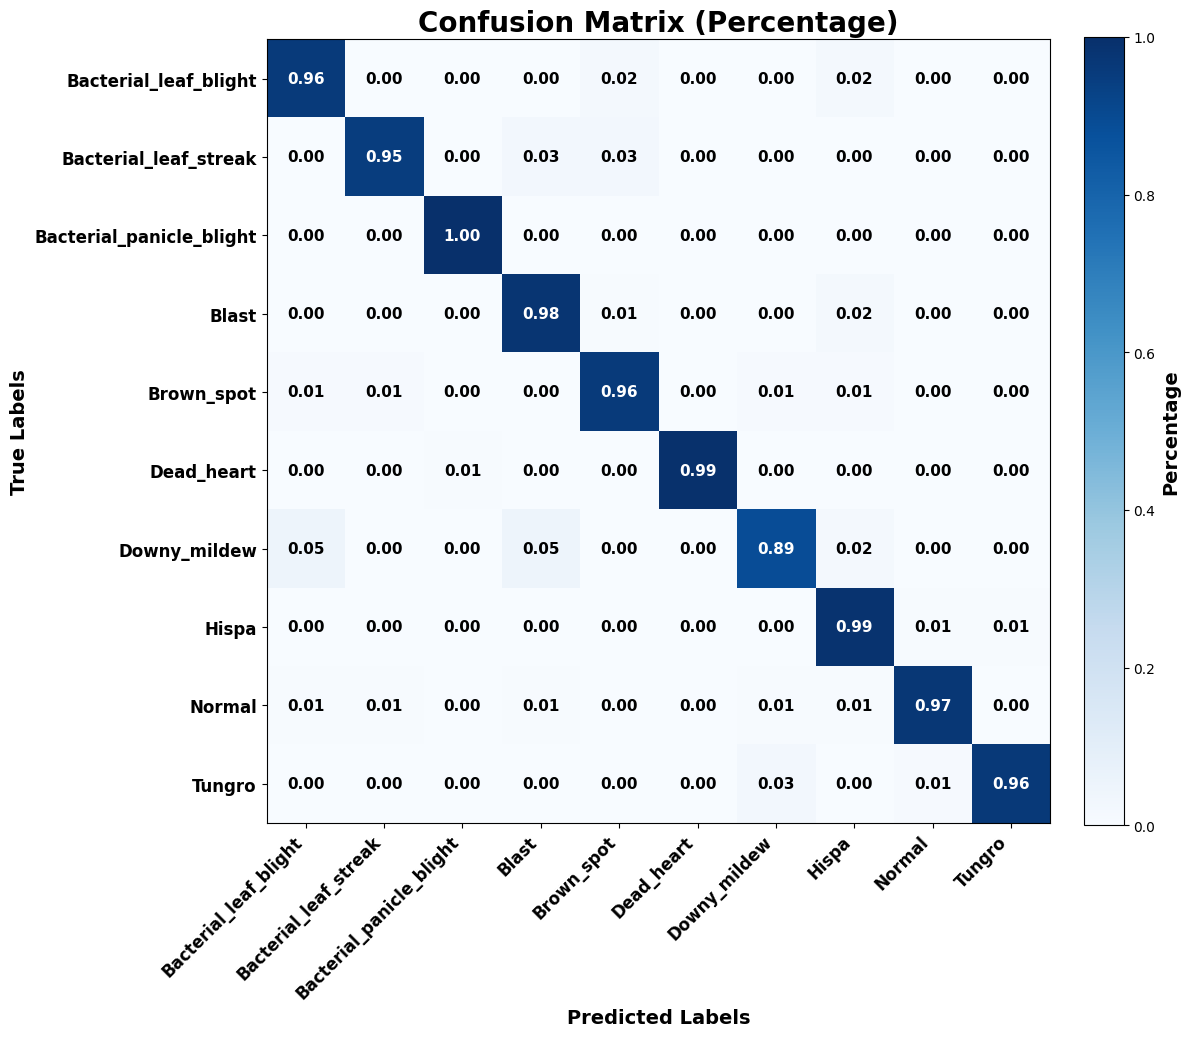

In [6]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# 获取 class_names
class_names = train_ds.classes  # 从数据集中获取类名

# 1. 在推理时收集模型的预测结果
y_true_list = []  # 用于存储真实标签
y_pred_list = []  # 用于存储预测标签

with torch.no_grad():
    for imgs, labels in tqdm(test_loader, desc="Test"):
        imgs = imgs.to(device)
        labels = labels.to(device)
        outputs = model(imgs)  # 预测 logits
        _, preds = torch.max(outputs, dim=1)  # 获取预测标签

        # 收集真实标签和预测标签
        y_true_list.append(labels.cpu())
        y_pred_list.append(preds.cpu())

# 2. 将 y_true_list 和 y_pred_list 转换为 numpy 数组（统一形状）
y_true_np = np.concatenate([x.numpy() for x in y_true_list], axis=0)
y_pred_np = np.concatenate([x.numpy() for x in y_pred_list], axis=0)

# 3. 计算百分比混淆矩阵
conf_matrix = confusion_matrix(y_true_np, y_pred_np, labels=range(num_classes))
conf_matrix_percentage = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]

# 4. 保存路径
save_fig_dir = './Result/5/confusion_matrix'
os.makedirs(save_fig_dir, exist_ok=True)
fig_path = os.path.join(save_fig_dir, 'confusion_matrix.tif')

# 5. 画布
plt.figure(figsize=(12, 12))
im = plt.imshow(conf_matrix_percentage, interpolation='nearest', cmap='Blues')

# 标题
plt.title('Confusion Matrix (Percentage)', fontsize=20, weight='bold')

# colorbar
cbar = plt.colorbar(im, fraction=0.046, pad=0.04)
cbar.set_label('Percentage', fontsize=14, weight='bold')

# 坐标轴
tick_marks = np.arange(num_classes)
plt.xticks(tick_marks, class_names, rotation=45, ha='right', fontsize=12, weight='bold')
plt.yticks(tick_marks, class_names, fontsize=12, weight='bold')
plt.xlabel('Predicted Labels', fontsize=14, weight='bold')
plt.ylabel('True Labels', fontsize=14, weight='bold')


for i in range(num_classes):
    for j in range(num_classes):
        val = conf_matrix_percentage[i, j]
        plt.text(j, i, f'{val:.2f}',
                 ha='center', va='center',
                 fontsize=11, weight='bold',
                 color='white' if val >= 0.5 else 'black')

plt.grid(False)
plt.tight_layout()

# 7. 保存 & 显示
plt.savefig(fig_path, dpi=300, format='tif', bbox_inches='tight')
print(f'Confusion matrix saved to {fig_path}')
plt.show()